# PyTorch. Автокодировщик для Sign Language MNIST

Обучим полносвязную сеть восстанавливать изображение по двум числам.
Кодировщик и декодировщик соберём через `nn.Sequential`.
После обучения рассмотрим восстановленные изображения и расположение их кодов на плоскости.

## Набор данных

Sign Language MNIST содержит изображения жестов для 24 букв американского жестового алфавита.
Размер изображения равен $28\times28$ пикселям.
В исходном наборе есть 27 455 обучающих и 7172 тестовых изображений [1].
Столбец `label` хранит номер буквы, а `pixel1`–`pixel784` содержат яркости от 0 до 255.
Номера 9 и 25 пропущены, поскольку жесты J и Z включают движение.

В этой работе сеть восстанавливает пиксели, а не предсказывает букву.
Метки сохраним для разбиения данных и подписей на графиках.

## Импорт

In [1]:
from copy import deepcopy
from pathlib import Path
from urllib.request import urlretrieve
from zipfile import ZipFile, is_zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from IPython.display import display

torch.manual_seed(42)

## 1. Из таблицы в изображение

### 1.1. Прочитаем данные

Архив берём со страницы исходного набора [1].
Два CSV прочитаем в таблицы `df` и `df_test`.
Значения пикселей пока оставим целыми.

In [2]:
data_dir = Path("data")
data_dir.mkdir(exist_ok=True)

source_train = "/kaggle/input/datasets/datamunge/sign-language-mnist/sign_mnist_train/sign_mnist_train.csv"
source_test = "/kaggle/input/datasets/datamunge/sign-language-mnist/sign_mnist_test/sign_mnist_test.csv"

df = pd.read_csv(source_train, dtype=np.uint8)
df_test = pd.read_csv(source_test, dtype=np.uint8)

In [3]:
pixel_columns = [column for column in df.columns if column != "label"]

print("Обучающий файл", df.shape)
print("Тестовый файл", df_test.shape)
display(df.loc[:, ["label"] + pixel_columns[:4] + pixel_columns[-3:]].head())
print("Пропуски", int(df.isna().sum().sum()), int(df_test.isna().sum().sum()))
print("Метки", sorted(df["label"].unique().tolist()))

Обучающий файл (27455, 785)
Тестовый файл (7172, 785)


,label,pixel1,pixel2,pixel3,pixel4,pixel782,pixel783,pixel784
0,3,107,118,127,134,204,203,202
1,6,155,157,156,156,103,135,149
2,2,187,188,188,187,195,194,195
3,2,211,211,212,212,222,229,163
4,13,164,167,170,172,163,164,179


Пропуски 0 0
Метки [0, 1, 2, 3, 4, 5, 6, 7, 8, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]


### 1.2. Покажем несколько изображений

Строка с 784 пикселями разворачивается в матрицу формы `(28, 28)`.
Порядок значений остаётся прежним.
Соберём восемь изображений в одну полосу.

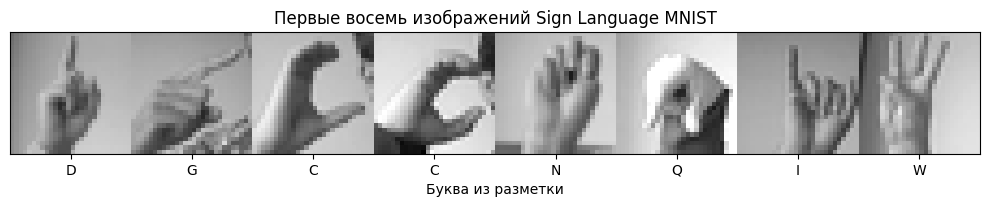

In [4]:
images = df.loc[:7, pixel_columns].to_numpy().reshape(8, 28, 28)
letters = [chr(ord("A") + int(label)) for label in df.loc[:7, "label"]]
image_strip = np.concatenate(list(images), axis=1)

plt.figure(figsize=(10, 2.6))
plt.imshow(image_strip, cmap="gray", vmin=0, vmax=255)
plt.xticks(28 * np.arange(8) + 13.5, letters)
plt.yticks([])
plt.xlabel("Буква из разметки")
plt.title("Первые восемь изображений Sign Language MNIST")
plt.tight_layout()
plt.show()

### 1.3. Посмотрим на число изображений

Букву получаем из её исходного номера.
После пропуска J номер следующей буквы не меняем.

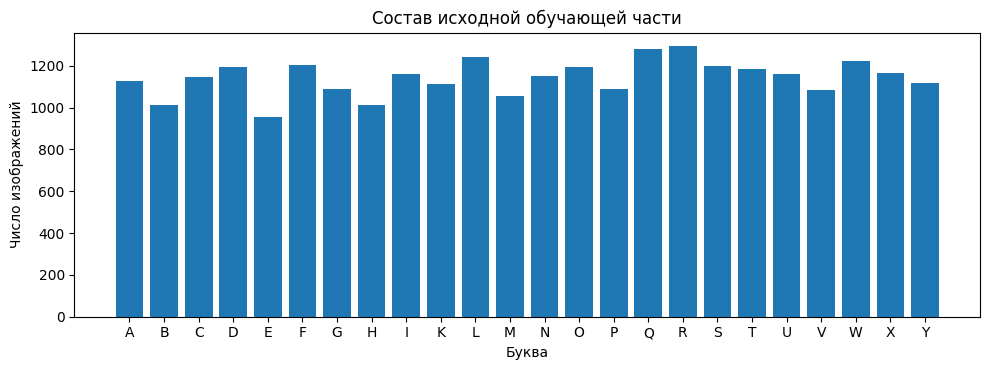

In [5]:
class_counts = df["label"].value_counts().sort_index()
letters = [chr(ord("A") + int(label)) for label in class_counts.index]

plt.figure(figsize=(10, 3.8))
plt.bar(letters, class_counts.to_numpy())
plt.xlabel("Буква")
plt.ylabel("Число изображений")
plt.title("Состав исходной обучающей части")
plt.tight_layout()
plt.show()

## 2. Подготовка данных

### 2.1. Отделим валидацию

Из таблицы `df` выделим 20% строк для валидации.
Остальные строки используем для обновления весов.
Таблица `df_test` останется отдельной тестовой частью.
Аргумент `stratify` сохраняет доли букв при разбиении.

Исходный набор расширен преобразованиями небольшого числа фотографий [1].
Разбиение строк не гарантирует разделения по исходной фотографии или человеку.
Поэтому эту валидацию не будем считать оценкой переноса на новых людей.

In [6]:
train_df, valid_df = train_test_split(
    df, test_size=0.2, random_state=42, stratify=df["label"]
)
train_df = train_df.reset_index(drop=True)
valid_df = valid_df.reset_index(drop=True)
test_df = df_test.reset_index(drop=True)

pd.DataFrame({
    "Часть": ["train", "valid", "test"],
    "Изображений": [len(train_df), len(valid_df), len(test_df)],
})

,Часть,Изображений
0,train,21964
1,valid,5491
2,test,7172


### 2.2. Опишем Dataset

Один объект будет содержать вектор пикселей и метку буквы.
Пиксели переведём в `float32` и разделим на 255.
Так их значения попадут в отрезок $[0,1]$.
Делитель известен заранее и не оценивается по выборке.

`__len__` возвращает число изображений.
`__getitem__` выбирает один объект по индексу [2].
Целевым ответом при обучении станет сам вектор пикселей.

In [7]:
class ImageDataset(Dataset):
    def __init__(self, frame):
        pixels = frame.drop(columns="label").to_numpy(dtype=np.float32)
        labels = frame["label"].to_numpy(dtype=np.int64)
        self.images = torch.from_numpy(pixels) / 255.0
        self.labels = torch.from_numpy(labels)

    def __len__(self):
        return len(self.images)

    def __getitem__(self, index):
        return self.images[index], self.labels[index]


train_dataset = ImageDataset(train_df)
valid_dataset = ImageDataset(valid_df)
test_dataset = ImageDataset(test_df)

### 2.3. Соберём пакеты

`DataLoader` объединяет отдельные объекты в пакеты [2].
При обучении перемешиваем строки.
Для валидации и итоговой оценки сохраняем их порядок.

Пакет пикселей имеет форму `(B, 784)`.
Метки имеют форму `(B,)`.
Буквой $B$ обозначено число изображений в пакете.

In [8]:
train_loader = DataLoader(train_dataset, batch_size=256, shuffle=True)
valid_loader = DataLoader(valid_dataset, batch_size=512, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=512, shuffle=False)
train_eval_loader = DataLoader(train_dataset, batch_size=512, shuffle=False)

batch_images, batch_labels = next(iter(train_loader))
print("Изображения", tuple(batch_images.shape), batch_images.dtype)
print("Метки", tuple(batch_labels.shape), batch_labels.dtype)

Изображения (256, 784) torch.float32
Метки (256,) torch.int64


## 3. Что восстанавливает автокодировщик

Кодировщик преобразует изображение $x$ в вектор $z$ из двух чисел.
Декодировщик получает только этот вектор и вычисляет восстановленное изображение $\hat x$.

$$z=f_\theta(x)\in\mathbb{R}^2,\qquad \hat x=g_\varphi(z)\in\mathbb{R}^{784}.$$

Обучать обе части будем по среднему квадрату ошибки между входом и восстановлением.
Для пакета из $B$ изображений получаем

$$L=\frac{1}{B\cdot784}\sum_{i=1}^{B}\sum_{p=1}^{784}(\hat x_{ip}-x_{ip})^2.$$

`nn.MSELoss()` усредняет квадраты разностей по всем элементам [4].
В функцию передадим два тензора формы `(B, 784)`.
Метки букв в это вычисление не входят.

In [9]:
loss_function = nn.MSELoss()

## 4. Кодировщик и декодировщик

### 4.1. Построим последовательную сеть

В кодировщике последовательно уменьшим ширину слоя до двух значений.
В декодировщике расширим представление обратно до 784 пикселей.
Между линейными слоями поставим `ReLU`.
Поэтому вся модель будет нелинейной, хотя её обучаемые слои заданы через `nn.Linear`.

Последний слой кодировщика оставим без активации.
Его два выхода смогут принимать как положительные, так и отрицательные значения.
На выходе декодировщика поставим `Sigmoid`, чтобы согласовать выход с диапазоном пикселей.

$$784\rightarrow256\rightarrow64\rightarrow\boxed{2}\rightarrow64\rightarrow256\rightarrow784.$$

`nn.Sequential` передаёт выход одного блока на вход следующего [3].
Объекты `encoder` и `decoder` включим в общую модель без копирования.

In [10]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(42)

encoder = nn.Sequential(
    nn.Linear(784, 256),
    nn.ReLU(),
    nn.Linear(256, 64),
    nn.ReLU(),
    nn.Linear(64, 2),
)

decoder = nn.Sequential(
    nn.Linear(2, 64),
    nn.ReLU(),
    nn.Linear(64, 256),
    nn.ReLU(),
    nn.Linear(256, 784),
    nn.Sigmoid(),
)

autoencoder = nn.Sequential(encoder, decoder).to(device)
autoencoder

Sequential(
  (0): Sequential(
    (0): Linear(in_features=784, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=2, bias=True)
  )
  (1): Sequential(
    (0): Linear(in_features=2, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=256, bias=True)
    (3): ReLU()
    (4): Linear(in_features=256, out_features=784, bias=True)
    (5): Sigmoid()
  )
)

### 4.2. Проследим формы тензоров

Входной пакет содержит 784 значения на изображение.
После кодировщика на каждый объект остаются два числа.
Декодировщик возвращает 784 значения.

Вызов `autoencoder(x)` выполняет ту же цепочку, что и `decoder(encoder(x))`.
Для этого просмотра производные не нужны.

In [11]:
batch_images, _ = next(iter(train_loader))
batch_images = batch_images.to(device)

with torch.no_grad():
    batch_codes = encoder(batch_images)
    batch_restored = decoder(batch_codes)

print("Вход", tuple(batch_images.shape))
print("Код", tuple(batch_codes.shape))
print("Восстановление", tuple(batch_restored.shape))
print("Число параметров", sum(parameter.numel() for parameter in autoencoder.parameters()))

Вход (256, 784)
Код (256, 2)
Восстановление (256, 784)
Число параметров 435858


## 5. Оптимизатор

Передадим Adam параметры всей модели.
Один обратный проход вычислит производные для кодировщика и декодировщика [5].
Во время обучения между ними не нужно вызывать `detach()`.
Иначе кодировщик перестанет получать производные от ошибки восстановления.

In [12]:
optimizer = torch.optim.Adam(autoencoder.parameters(), lr=0.001)

## 6. Обучение и валидация

Для каждого обучающего пакета очистим градиенты, получим восстановление и вычислим ошибку.
Затем вызовем `backward()` и обновим параметры через `step()` [5].
Вместо метки буквы в функцию потерь передадим исходное изображение.

После каждой эпохи пройдём по валидационной части без обновления весов.
Для этого используем `eval()` и `torch.no_grad()`.
Состояние с наименьшим MSE на валидации сохраним через `deepcopy` [6].

В историю запишем MSE и среднюю абсолютную ошибку MAE.
Ошибки пакетов усредним с учётом числа изображений.
Значения для `train` собираются при изменяющихся весах внутри эпохи.
Итоговые метрики выбранной модели позднее вычислим заново.

In [13]:
epochs = 50
history = {"train_mse": [], "valid_mse": [], "train_mae": [], "valid_mae": []}
best_valid_mse = float("inf")
best_state = deepcopy(autoencoder.state_dict())
best_epoch = 0

for epoch in range(epochs):
    autoencoder.train()
    train_mse_sum = 0.0
    train_mae_sum = 0.0
    train_count = 0

    for images, _ in train_loader:
        images = images.to(device)
        optimizer.zero_grad()
        restored = autoencoder(images)
        loss = loss_function(restored, images)
        loss.backward()
        optimizer.step()

        count = images.size(0)
        train_mse_sum += loss.item() * count
        train_mae_sum += (restored.detach() - images).abs().mean().item() * count
        train_count += count

    autoencoder.eval()
    valid_mse_sum = 0.0
    valid_mae_sum = 0.0
    valid_count = 0

    with torch.no_grad():
        for images, _ in valid_loader:
            images = images.to(device)
            restored = autoencoder(images)
            count = images.size(0)
            valid_mse_sum += loss_function(restored, images).item() * count
            valid_mae_sum += (restored - images).abs().mean().item() * count
            valid_count += count

    history["train_mse"].append(train_mse_sum / train_count)
    history["valid_mse"].append(valid_mse_sum / valid_count)
    history["train_mae"].append(train_mae_sum / train_count)
    history["valid_mae"].append(valid_mae_sum / valid_count)

    if history["valid_mse"][-1] < best_valid_mse:
        best_valid_mse = history["valid_mse"][-1]
        best_state = deepcopy(autoencoder.state_dict())
        best_epoch = epoch + 1

    if epoch == 0 or (epoch + 1) % 5 == 0:
        print(
            f"Эпоха {epoch + 1:02d} | "
            f"train MSE {history['train_mse'][-1]:.5f} | "
            f"valid MSE {history['valid_mse'][-1]:.5f}"
        )

Эпоха 01 | train MSE 0.03010 | valid MSE 0.02540
Эпоха 05 | train MSE 0.01973 | valid MSE 0.01966
Эпоха 10 | train MSE 0.01883 | valid MSE 0.01882
Эпоха 15 | train MSE 0.01837 | valid MSE 0.01835
Эпоха 20 | train MSE 0.01769 | valid MSE 0.01786
Эпоха 25 | train MSE 0.01714 | valid MSE 0.01714
Эпоха 30 | train MSE 0.01686 | valid MSE 0.01683
Эпоха 35 | train MSE 0.01662 | valid MSE 0.01668
Эпоха 40 | train MSE 0.01644 | valid MSE 0.01659
Эпоха 45 | train MSE 0.01627 | valid MSE 0.01635
Эпоха 50 | train MSE 0.01613 | valid MSE 0.01622


### 6.1. Вернём выбранные параметры

Лучшая валидационная эпоха может отличаться от последней.
Загрузим её параметры в тот же объект `autoencoder`.
У входящих в него `encoder` и `decoder` параметры обновятся одновременно.

In [14]:
autoencoder.load_state_dict(best_state)
autoencoder.eval()
print("Выбранная эпоха", best_epoch)

Выбранная эпоха 50


## 7. Тестирование

Пройдём по тестовым изображениям с выбранными параметрами.
Для каждого пакета сохраним исходные пиксели, двумерные коды, восстановления и метки.
Все четыре массива собираем в одном цикле, чтобы сохранить соответствие объектов.

После `torch.cat` первая ось будет содержать все тестовые изображения.
Для таблиц и графиков перенесём значения на CPU и преобразуем их в NumPy.

In [15]:
test_inputs = []
test_outputs = []
test_codes = []
test_labels = []

autoencoder.eval()
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        codes = encoder(images)
        restored = decoder(codes)

        test_inputs.append(images.cpu())
        test_outputs.append(restored.cpu())
        test_codes.append(codes.cpu())
        test_labels.append(labels.cpu())

x_test = torch.cat(test_inputs).numpy()
x_test_restored = torch.cat(test_outputs).numpy()
z_test = torch.cat(test_codes).numpy()
y_test = torch.cat(test_labels).numpy()

print("Исходные изображения", x_test.shape)
print("Восстановленные изображения", x_test_restored.shape)
print("Двумерные коды", z_test.shape)

Исходные изображения (7172, 784)
Восстановленные изображения (7172, 784)
Двумерные коды (7172, 2)


## 8. Метрики восстановления

### 8.1. Оценим выбранную модель на train и test

MSE и MAE усредним по всем пикселям всех изображений.
RMSE получим как квадратный корень из общего MSE.
Метрики относятся к яркостям в диапазоне $[0,1]$.

Для сравнения возьмём модель, которая всегда возвращает среднее обучающее изображение.
Это изображение вычислим только по `train`.
Его MSE покажет, насколько полезно учитывать вход, а не выдавать один и тот же ответ.

In [16]:
mean_image = train_dataset.images.mean(dim=0).to(device)
train_squared_error = 0.0
train_absolute_error = 0.0
train_baseline_error = 0.0
train_elements = 0
train_codes = []

autoencoder.eval()
with torch.no_grad():
    for images, _ in train_eval_loader:
        images = images.to(device)
        codes = encoder(images)
        restored = decoder(codes)
        difference = restored - images

        train_squared_error += difference.square().sum().item()
        train_absolute_error += difference.abs().sum().item()
        train_baseline_error += (images - mean_image).square().sum().item()
        train_elements += images.numel()
        train_codes.append(codes.cpu())

z_train = torch.cat(train_codes).numpy()
train_mse = train_squared_error / train_elements
train_mae = train_absolute_error / train_elements
test_difference = x_test_restored - x_test
test_mse = np.mean(test_difference ** 2)
test_mae = np.mean(np.abs(test_difference))
test_baseline_mse = np.mean((x_test - mean_image.cpu().numpy()) ** 2)

metrics = pd.DataFrame({
    "Часть": ["train", "test"],
    "MSE": [train_mse, test_mse],
    "RMSE": [np.sqrt(train_mse), np.sqrt(test_mse)],
    "MAE": [train_mae, test_mae],
    "MSE среднего изображения": [train_baseline_error / train_elements, test_baseline_mse],
})
metrics.round(5)

,Часть,MSE,RMSE,MAE,MSE среднего изображения
0,train,0.01612,0.12696,0.09126,0.03352
1,test,0.01738,0.13182,0.09484,0.03405


### 8.2. Рассмотрим историю обучения

На первом графике покажем средний квадрат ошибки.
На втором рассмотрим среднюю абсолютную ошибку.
Вертикальная линия отмечает эпоху, выбранную по валидации.
Тестовая часть в выборе эпохи не участвует.

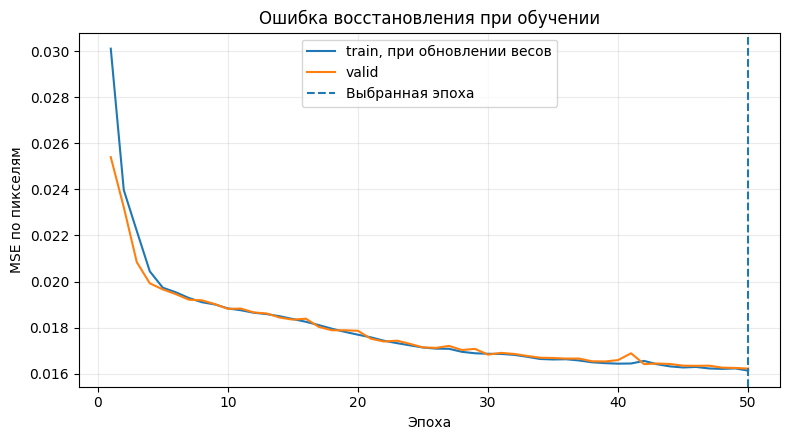

In [17]:
epoch_numbers = np.arange(1, len(history["train_mse"]) + 1)

plt.figure(figsize=(8, 4.5))
plt.plot(epoch_numbers, history["train_mse"], label="train, при обновлении весов")
plt.plot(epoch_numbers, history["valid_mse"], label="valid")
plt.axvline(best_epoch, linestyle="--", label="Выбранная эпоха")
plt.xlabel("Эпоха")
plt.ylabel("MSE по пикселям")
plt.title("Ошибка восстановления при обучении")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

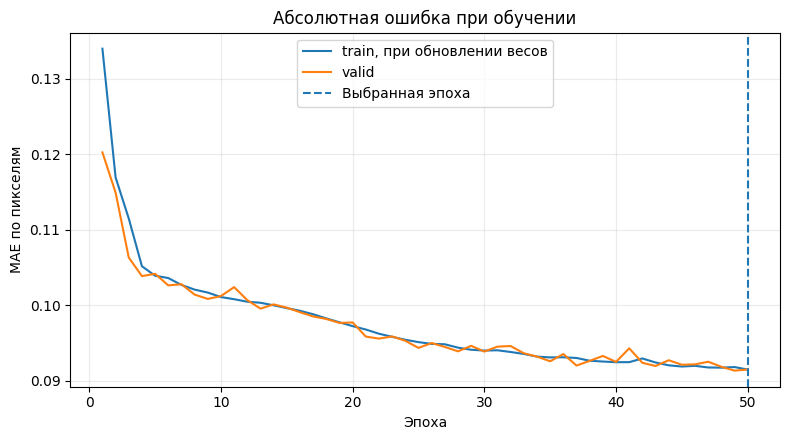

In [18]:
plt.figure(figsize=(8, 4.5))
plt.plot(epoch_numbers, history["train_mae"], label="train, при обновлении весов")
plt.plot(epoch_numbers, history["valid_mae"], label="valid")
plt.axvline(best_epoch, linestyle="--", label="Выбранная эпоха")
plt.xlabel("Эпоха")
plt.ylabel("MAE по пикселям")
plt.title("Абсолютная ошибка при обучении")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 9. Изображения и двумерное представление

### 9.1. Сопоставим вход и восстановление

Выберем первые восемь тестовых изображений без сортировки по ошибке.
Верхняя строка содержит исходные изображения, нижняя — ответы модели.
Для обеих строк используем одинаковый диапазон яркости.

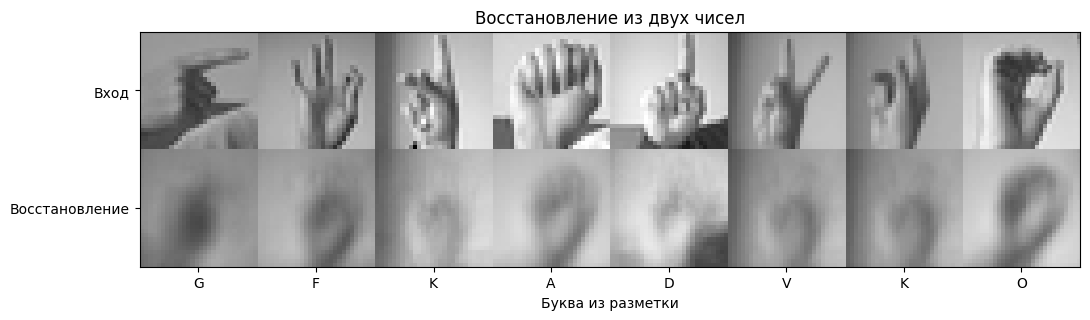

In [19]:
original_images = x_test[:8].reshape(8, 28, 28)
restored_images = x_test_restored[:8].reshape(8, 28, 28)
original_strip = np.concatenate(list(original_images), axis=1)
restored_strip = np.concatenate(list(restored_images), axis=1)
comparison = np.concatenate([original_strip, restored_strip], axis=0)
letters = [chr(ord("A") + int(label)) for label in y_test[:8]]

plt.figure(figsize=(11, 3.5))
plt.imshow(comparison, cmap="gray", vmin=0, vmax=1)
plt.xticks(28 * np.arange(8) + 13.5, letters)
plt.yticks([13.5, 41.5], ["Вход", "Восстановление"])
plt.xlabel("Буква из разметки")
plt.title("Восстановление из двух чисел")
plt.tight_layout()
plt.show()

### 9.2. Покажем распределение ошибок

Для каждого изображения вычислим собственный MSE по 784 пикселям.
Гистограмма позволит увидеть разброс ошибок, который скрывается за общим средним.

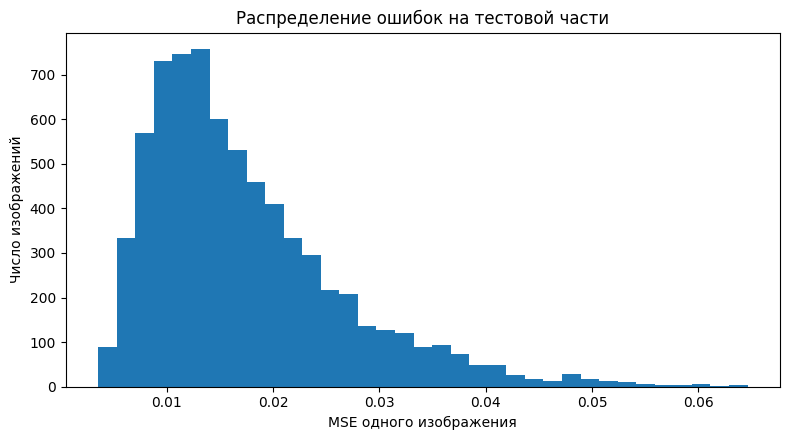

In [20]:
test_image_mse = np.mean((x_test_restored - x_test) ** 2, axis=1)

plt.figure(figsize=(8, 4.5))
plt.hist(test_image_mse, bins=35)
plt.xlabel("MSE одного изображения")
plt.ylabel("Число изображений")
plt.title("Распределение ошибок на тестовой части")
plt.tight_layout()
plt.show()

### 9.3. Разместим коды на плоскости

Каждому изображению соответствует точка $(z_1,z_2)$.
Используем непосредственно два выхода кодировщика.
Дополнительное снижение размерности здесь не требуется.

Для читаемости покажем случайную часть тестовых объектов.
Цвет и форма маркера обозначают букву.
Разметка не участвовала в функции потерь, поэтому разделение всех букв не было целью обучения.

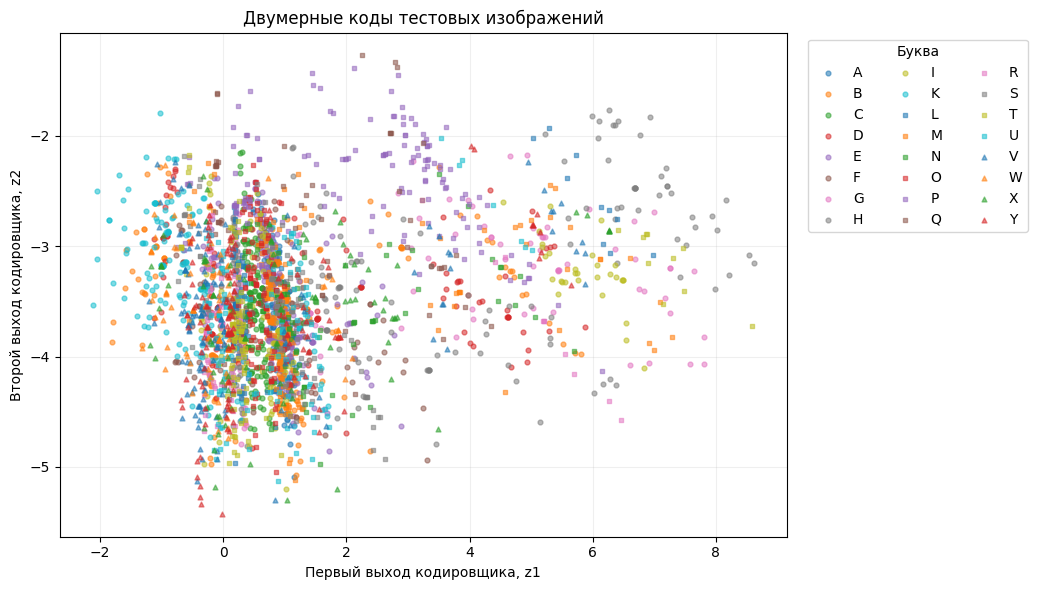

In [21]:
rng = np.random.default_rng(42)
shown = rng.choice(len(z_test), size=min(3000, len(z_test)), replace=False)
markers = ["o", "s", "^"]

plt.figure(figsize=(10.5, 6))
for number, label in enumerate(np.unique(y_test)):
    selected = shown[y_test[shown] == label]
    plt.scatter(
        z_test[selected, 0], z_test[selected, 1],
        s=12, alpha=0.55, marker=markers[number // 10],
        label=chr(ord("A") + int(label)),
    )
plt.xlabel("Первый выход кодировщика, z1")
plt.ylabel("Второй выход кодировщика, z2")
plt.title("Двумерные коды тестовых изображений")
plt.legend(title="Буква", ncol=3, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

### 9.4. Свяжем положение кода с ошибкой

Покажем те же точки, но обозначим цветом MSE каждого изображения.
Так можно сопоставить расположение кодов и качество восстановления.
Две координаты не обязаны сохранять различия между всеми жестами.

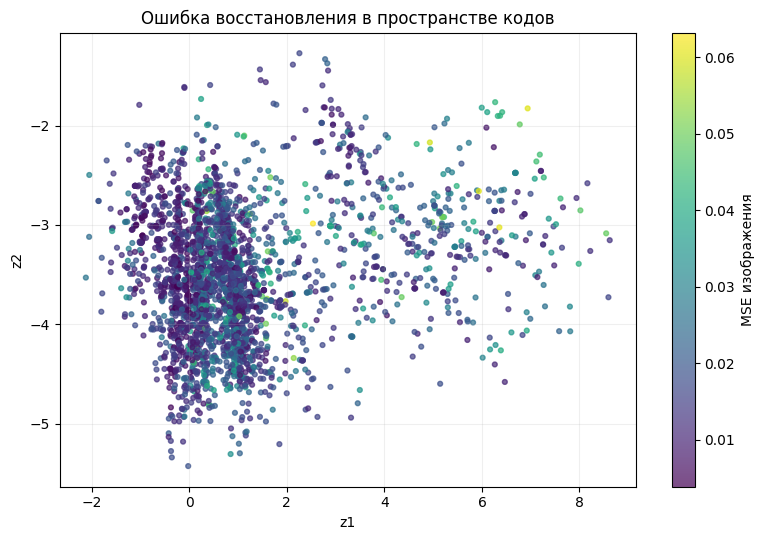

In [22]:
plt.figure(figsize=(8, 5.5))
points = plt.scatter(
    z_test[shown, 0], z_test[shown, 1],
    c=test_image_mse[shown], s=12, alpha=0.7,
)
plt.colorbar(points, label="MSE изображения")
plt.xlabel("z1")
plt.ylabel("z2")
plt.title("Ошибка восстановления в пространстве кодов")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

### 9.5. Передадим декодировщику сетку кодов

Границы сетки возьмём по 2-му и 98-му процентилям обучающих кодов.
В каждой точке вычислим изображение через `decoder`.
Верхняя строка сетки соответствует большим значениям $z_2$.

Полученная карта показывает, как меняется ответ при изменении двух координат.
Некоторые точки сетки могут лежать далеко от кодов реальных изображений.
В таких местах правдоподобное изображение не гарантируется.

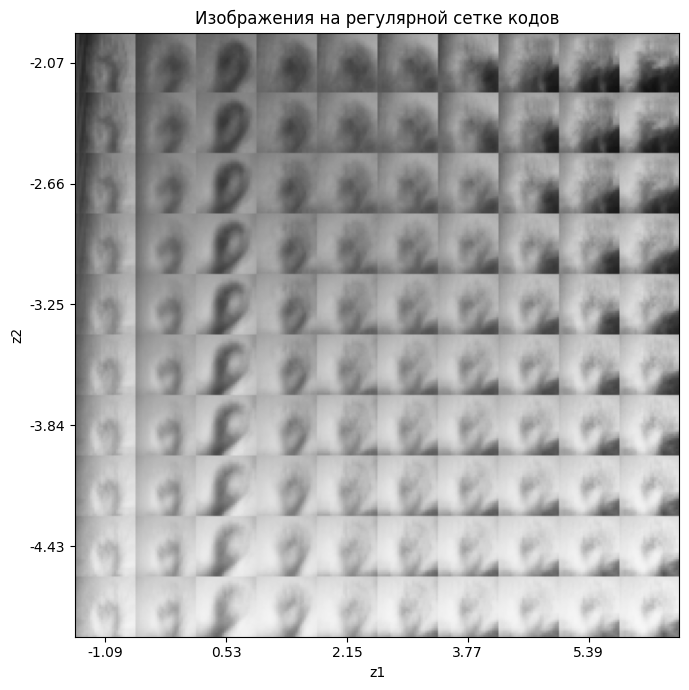

In [23]:
z_low, z_high = np.quantile(z_train, [0.02, 0.98], axis=0)
z1_values = np.linspace(z_low[0], z_high[0], 10)
z2_values = np.linspace(z_low[1], z_high[1], 10)
z1_grid, z2_grid = np.meshgrid(z1_values, z2_values[::-1])
grid_codes = np.column_stack([z1_grid.ravel(), z2_grid.ravel()])
grid_tensor = torch.tensor(grid_codes, dtype=torch.float32, device=device)

with torch.no_grad():
    decoded_grid = decoder(grid_tensor).cpu().numpy().reshape(10, 10, 28, 28)

image_map = decoded_grid.transpose(0, 2, 1, 3).reshape(280, 280)
tick_positions = 28 * np.arange(0, 10, 2) + 13.5

plt.figure(figsize=(7, 7))
plt.imshow(image_map, cmap="gray", vmin=0, vmax=1)
plt.xticks(tick_positions, [f"{value:.2f}" for value in z1_values[::2]])
plt.yticks(tick_positions, [f"{value:.2f}" for value in z2_values[::-1][::2]])
plt.xlabel("z1")
plt.ylabel("z2")
plt.title("Изображения на регулярной сетке кодов")
plt.tight_layout()
plt.show()

### 9.6. Построим линии уровня ошибки

Зафиксируем первое тестовое изображение $x^{(0)}$.
В каждой точке плоскости декодируем код и сравним результат с этим изображением.

$$E(z_1,z_2)=\frac{1}{784}\sum_{p=1}^{784}\left(g_\varphi(z_1,z_2)_p-x^{(0)}_p\right)^2.$$

Линия уровня объединяет коды с одинаковой ошибкой относительно выбранного изображения.
Это не вероятность класса и не карта ошибки для всей выборки.
Крестиком отметим код, который для этого изображения вычислил `encoder`.

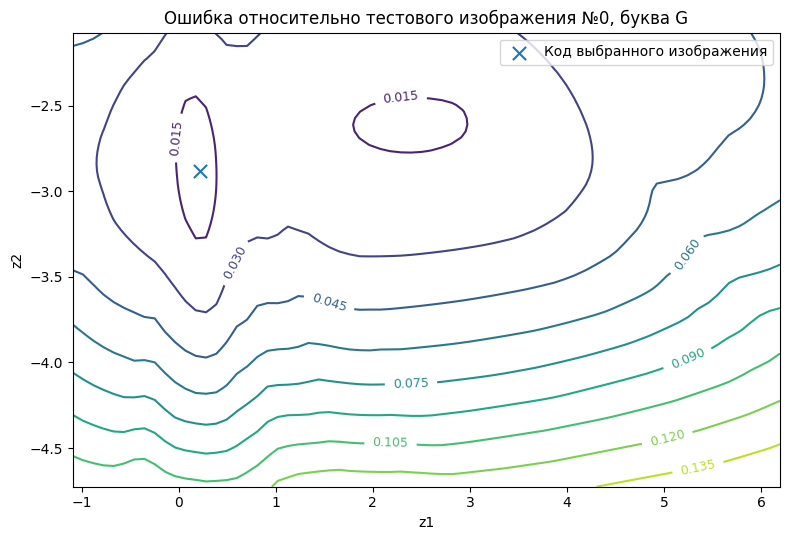

In [24]:
z1_axis = np.linspace(z_low[0], z_high[0], 70)
z2_axis = np.linspace(z_low[1], z_high[1], 70)
z1_grid, z2_grid = np.meshgrid(z1_axis, z2_axis)
grid_codes = np.column_stack([z1_grid.ravel(), z2_grid.ravel()])
grid_tensor = torch.tensor(grid_codes, dtype=torch.float32, device=device)
reference = torch.tensor(x_test[:1], dtype=torch.float32, device=device)
grid_errors = []

with torch.no_grad():
    for start in range(0, len(grid_tensor), 512):
        restored = decoder(grid_tensor[start:start + 512])
        errors = (restored - reference).square().mean(dim=1)
        grid_errors.append(errors.cpu())

error_surface = torch.cat(grid_errors).numpy().reshape(z1_grid.shape)
reference_letter = chr(ord("A") + int(y_test[0]))

plt.figure(figsize=(8, 5.5))
contours = plt.contour(z1_grid, z2_grid, error_surface, levels=9)
plt.clabel(contours, fmt="%.3f", fontsize=9)
plt.scatter(z_test[0, 0], z_test[0, 1], marker="x", s=90, label="Код выбранного изображения")
plt.xlabel("z1")
plt.ylabel("z2")
plt.title(f"Ошибка относительно тестового изображения №0, буква {reference_letter}")
plt.legend()
plt.tight_layout()
plt.show()

### 9.7. Пройдём между двумя кодами

Выберем два тестовых изображения с разными буквами в разметке.
Между их кодами построим девять промежуточных точек.

$$z(t)=(1-t)z_a+tz_b,\qquad 0\leq t\leq1.$$

Декодировщик получит каждую точку отдельно.
На крайних позициях будут восстановления двух исходных изображений.
Промежуточные изображения не обязаны соответствовать допустимым жестам.

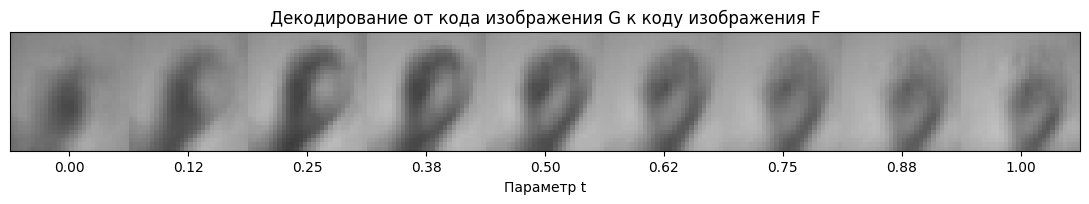

In [25]:
first_index = 0
second_index = int(np.flatnonzero(y_test != y_test[first_index])[0])
t_values = np.linspace(0, 1, 9, dtype=np.float32)
interpolated_codes = (
    (1 - t_values[:, None]) * z_test[first_index]
    + t_values[:, None] * z_test[second_index]
)
interpolated_tensor = torch.tensor(interpolated_codes, dtype=torch.float32, device=device)

with torch.no_grad():
    interpolated_images = decoder(interpolated_tensor).cpu().numpy().reshape(9, 28, 28)

interpolation_strip = np.concatenate(list(interpolated_images), axis=1)
first_letter = chr(ord("A") + int(y_test[first_index]))
second_letter = chr(ord("A") + int(y_test[second_index]))

plt.figure(figsize=(11, 2.7))
plt.imshow(interpolation_strip, cmap="gray", vmin=0, vmax=1)
plt.xticks(28 * np.arange(9) + 13.5, [f"{value:.2f}" for value in t_values])
plt.yticks([])
plt.xlabel("Параметр t")
plt.title(f"Декодирование от кода изображения {first_letter} к коду изображения {second_letter}")
plt.tight_layout()
plt.show()

## 10. Сохранение модели

Сохраним веса выбранной модели и описание подготовки пикселей.
В `state_dict` находятся параметры, но не код архитектуры [6].
При загрузке сначала создадим сеть с теми же слоями.

In [26]:
checkpoint = {
    "model_state": {
        name: value.detach().cpu().clone()
        for name, value in autoencoder.state_dict().items()
    },
    "image_shape": [28, 28],
    "pixel_columns": list(pixel_columns),
    "pixel_divisor": 255.0,
    "latent_dim": 2,
    "best_epoch": int(best_epoch),
}
torch.save(checkpoint, "sign_mnist_autoencoder_2d.pt")

### 10.1. Восстановим сеть из сохранённых весов

Создадим новые объекты кодировщика и декодировщика.
Для нового изображения сохраним прежний порядок пикселей и деление на 255.
После загрузки переведём сеть в режим `eval()`.

Двумерный код [[ 0.22258574 -2.8821867 ]]


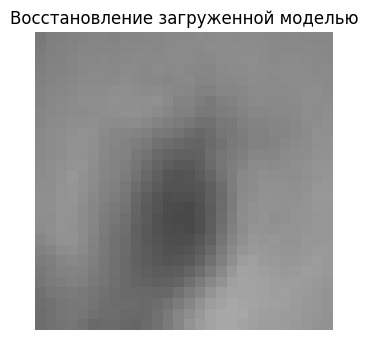

In [27]:
checkpoint = torch.load("sign_mnist_autoencoder_2d.pt", map_location="cpu", weights_only=True)

loaded_encoder = nn.Sequential(
    nn.Linear(784, 256), nn.ReLU(),
    nn.Linear(256, 64), nn.ReLU(),
    nn.Linear(64, 2),
)
loaded_decoder = nn.Sequential(
    nn.Linear(2, 64), nn.ReLU(),
    nn.Linear(64, 256), nn.ReLU(),
    nn.Linear(256, 784), nn.Sigmoid(),
)
loaded_model = nn.Sequential(loaded_encoder, loaded_decoder)
loaded_model.load_state_dict(checkpoint["model_state"])
loaded_model.eval()

pixels = test_df.loc[[0], checkpoint["pixel_columns"]].to_numpy(dtype=np.float32)
image_tensor = torch.from_numpy(pixels) / checkpoint["pixel_divisor"]
with torch.no_grad():
    image_code = loaded_encoder(image_tensor)
    restored_image = loaded_decoder(image_code).reshape(checkpoint["image_shape"]).numpy()

print("Двумерный код", image_code.numpy())
plt.figure(figsize=(3.5, 3.5))
plt.imshow(restored_image, cmap="gray", vmin=0, vmax=1)
plt.axis("off")
plt.title("Восстановление загруженной моделью")
plt.tight_layout()
plt.show()

## Документация

[1] [Sign Language MNIST. Описание и исходные файлы](https://www.kaggle.com/datasets/datamunge/sign-language-mnist).

[2] [PyTorch. Dataset и DataLoader](https://docs.pytorch.org/tutorials/beginner/basics/data_tutorial.html).

[3] [PyTorch. nn.Sequential](https://docs.pytorch.org/docs/stable/generated/torch.nn.Sequential.html).

[4] [PyTorch. nn.MSELoss](https://docs.pytorch.org/docs/stable/generated/torch.nn.MSELoss.html).

[5] [PyTorch. Обновление параметров модели](https://docs.pytorch.org/tutorials/beginner/basics/optimization_tutorial.html).

[6] [PyTorch. Сохранение и загрузка моделей](https://docs.pytorch.org/tutorials/beginner/saving_loading_models.html).